In [20]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

In [2]:
df = pd.read_csv("data/Final_data.csv")
df.columns = df.columns.str.strip().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')


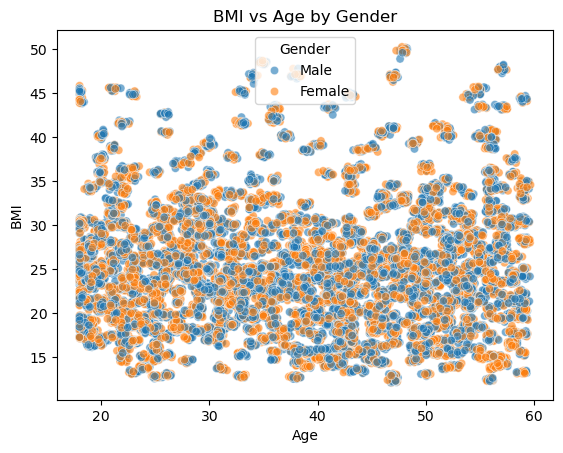

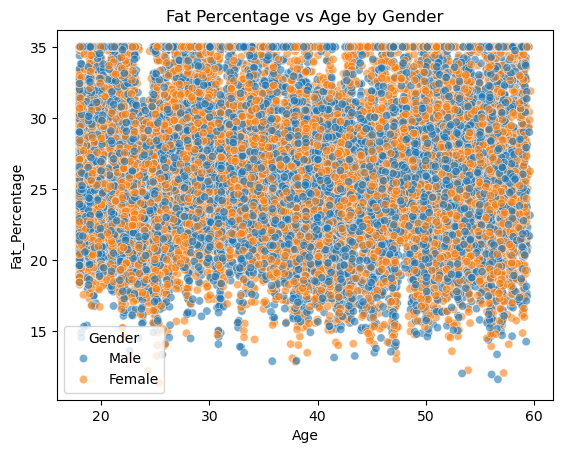

In [22]:
sns.scatterplot(data=df, x='Age', y='BMI', hue='Gender', alpha=0.6)
plt.title("BMI vs Age by Gender")
plt.show()

sns.scatterplot(data=df, x='Age', y='Fat_Percentage', hue='Gender', alpha=0.6)
plt.title("Fat Percentage vs Age by Gender")
plt.show()


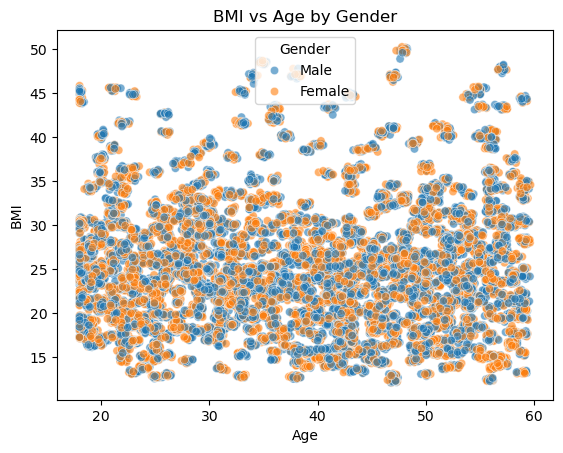

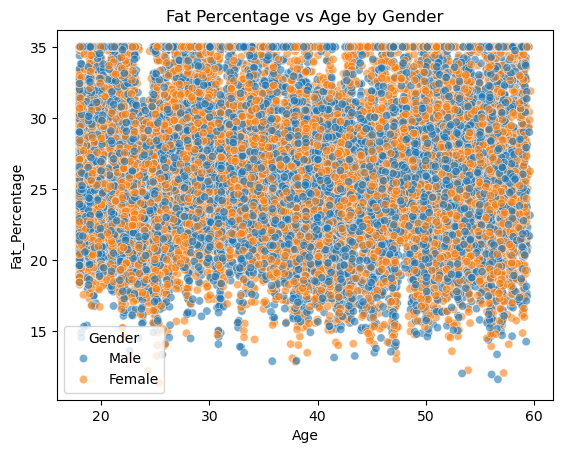

In [23]:
sns.scatterplot(data=df, x='Age', y='BMI', hue='Gender', alpha=0.6)
plt.title("BMI vs Age by Gender")
plt.show()

sns.scatterplot(data=df, x='Age', y='Fat_Percentage', hue='Gender', alpha=0.6)
plt.title("Fat Percentage vs Age by Gender")
plt.show()

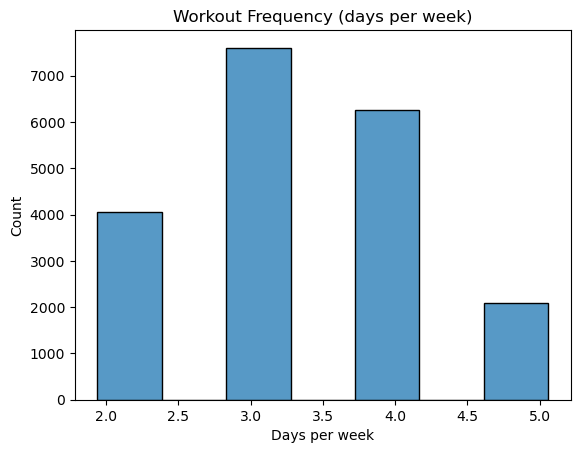

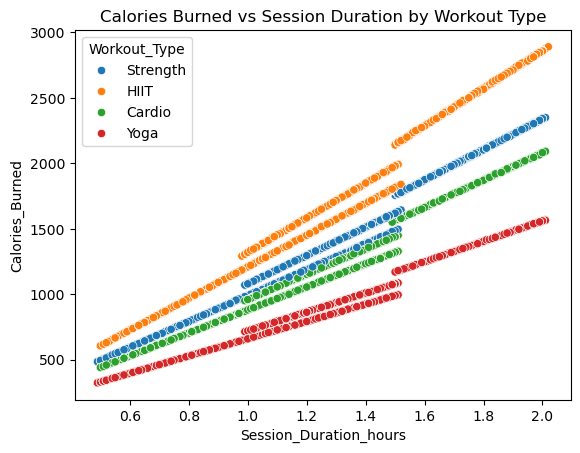

In [24]:
sns.histplot(df['Workout_Frequency_days/week'], bins=7, kde=False)
plt.title("Workout Frequency (days per week)")
plt.xlabel("Days per week")
plt.show()

sns.scatterplot(data=df, x='Session_Duration_hours', y='Calories_Burned', hue='Workout_Type')
plt.title("Calories Burned vs Session Duration by Workout Type")
plt.show()


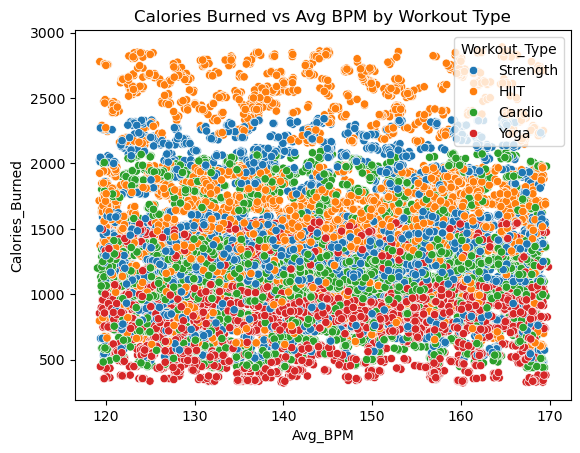

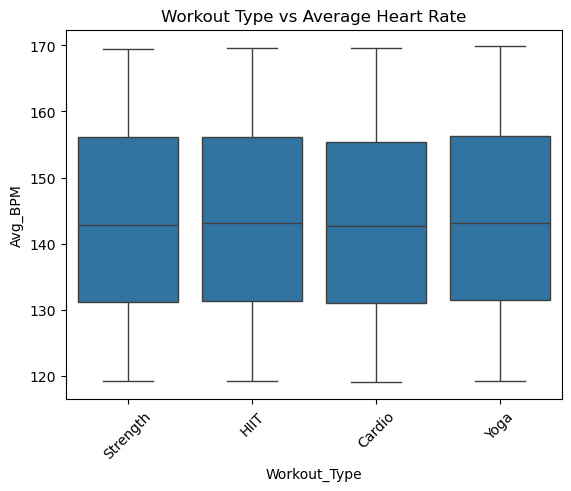

In [25]:
sns.scatterplot(data=df, x='Avg_BPM', y='Calories_Burned', hue='Workout_Type')
plt.title("Calories Burned vs Avg BPM by Workout Type")
plt.show()

sns.boxplot(data=df, x='Workout_Type', y='Avg_BPM')
plt.title("Workout Type vs Average Heart Rate")
plt.xticks(rotation=45)
plt.show()

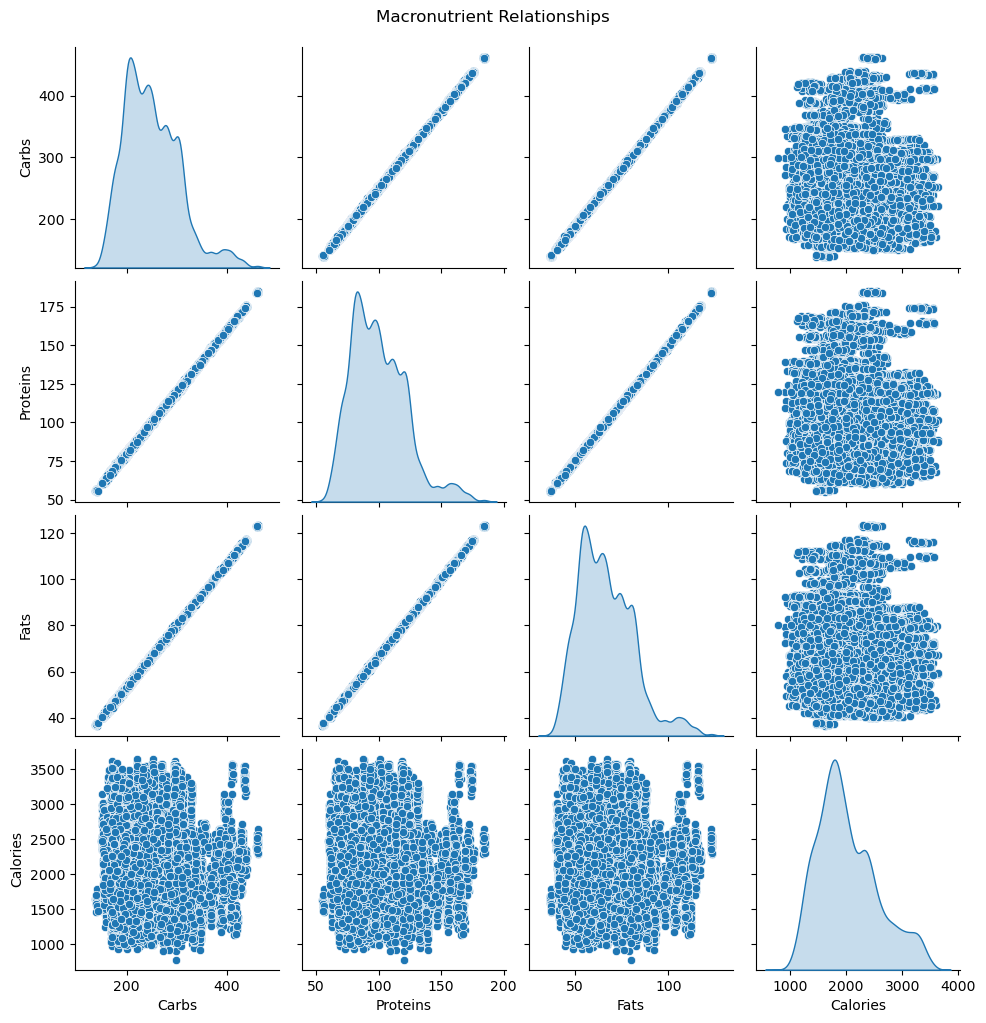

In [26]:
sns.pairplot(df[['Carbs','Proteins','Fats','Calories']], diag_kind='kde')
plt.suptitle("Macronutrient Relationships", y=1.02)
plt.show()

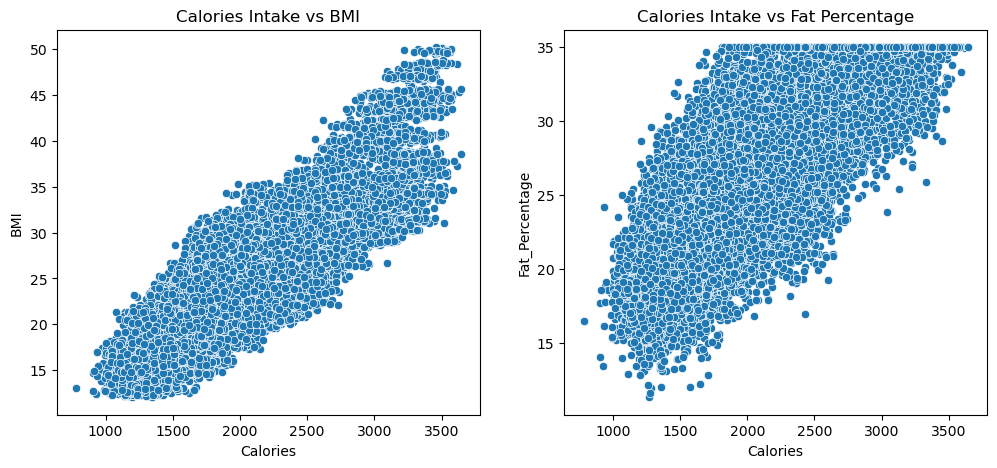

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.scatterplot(data=df, x='Calories', y='BMI', ax=axes[0])
sns.scatterplot(data=df, x='Calories', y='Fat_Percentage', ax=axes[1])
axes[0].set_title("Calories Intake vs BMI")
axes[1].set_title("Calories Intake vs Fat Percentage")
plt.show()

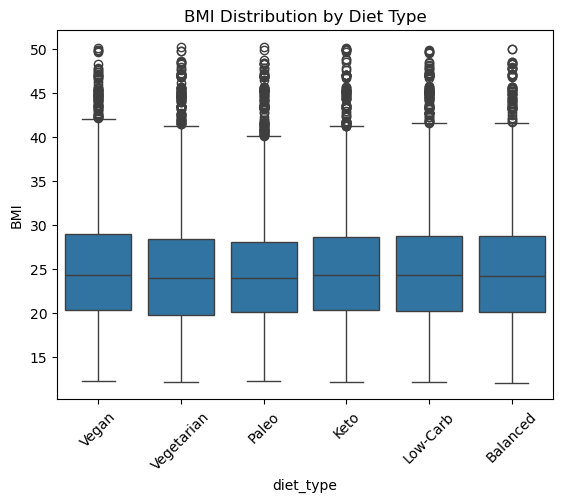

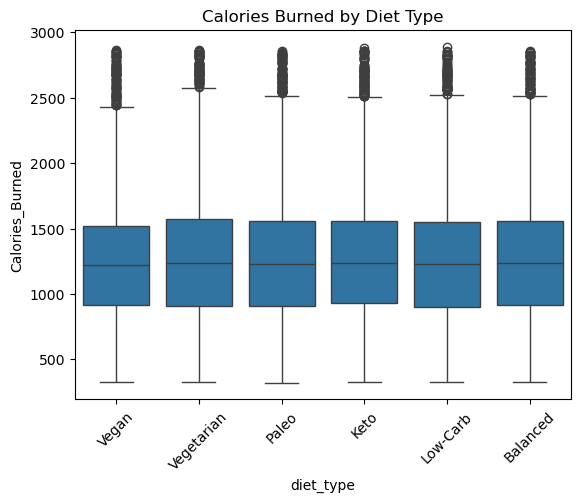

In [28]:
sns.boxplot(data=df, x='diet_type', y='BMI')
plt.xticks(rotation=45)
plt.title("BMI Distribution by Diet Type")
plt.show()

sns.boxplot(data=df, x='diet_type', y='Calories_Burned')
plt.xticks(rotation=45)
plt.title("Calories Burned by Diet Type")
plt.show()

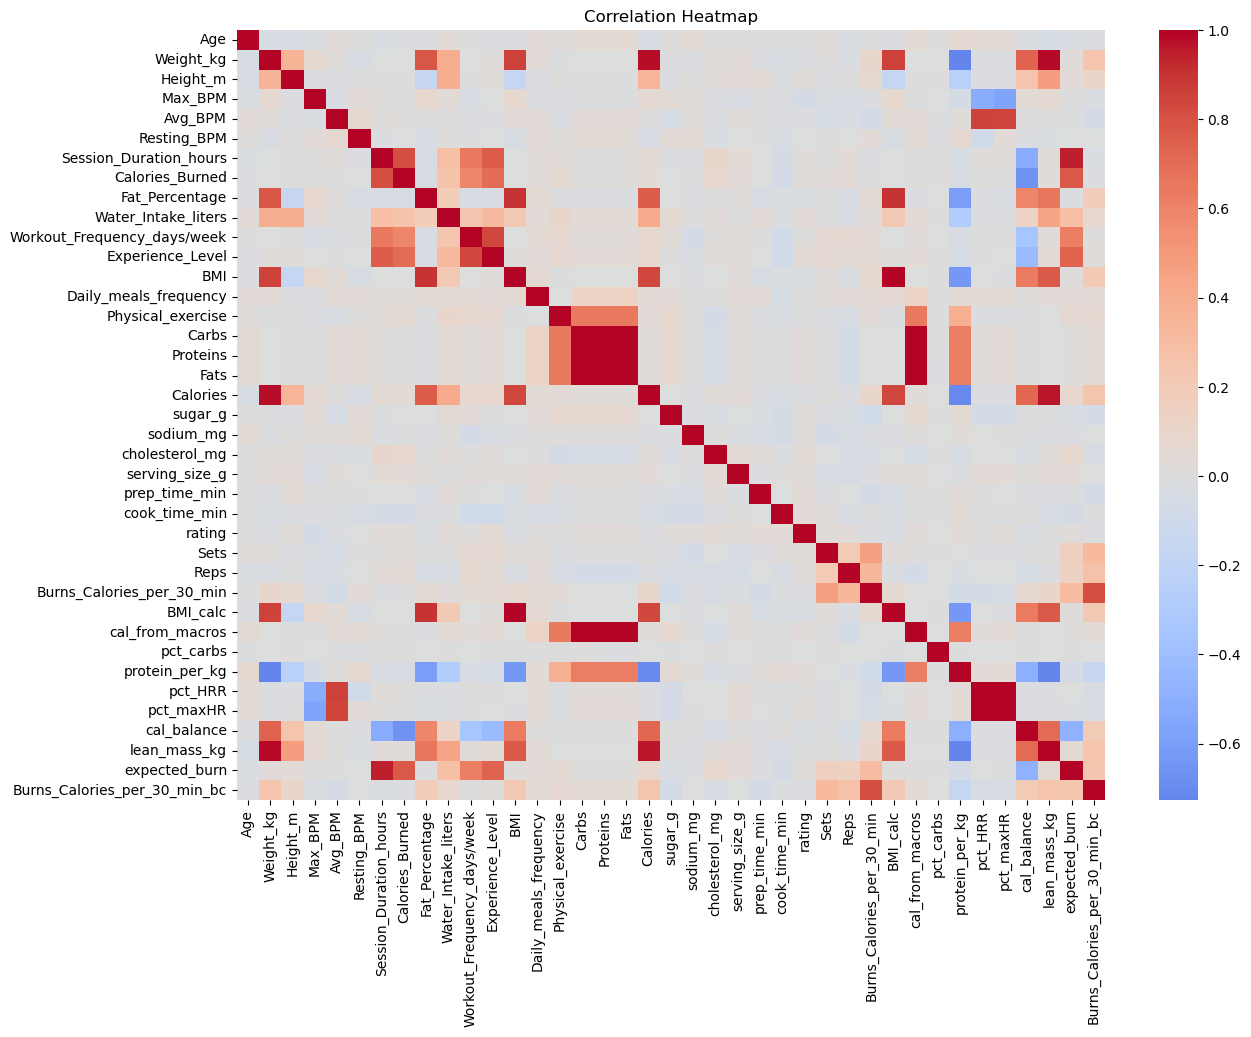

In [29]:
plt.figure(figsize=(14,10))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

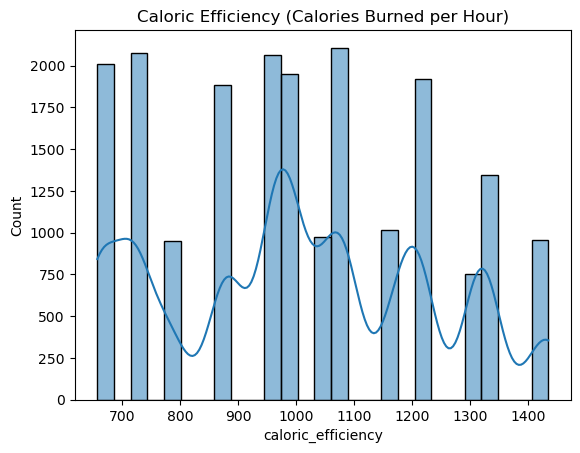

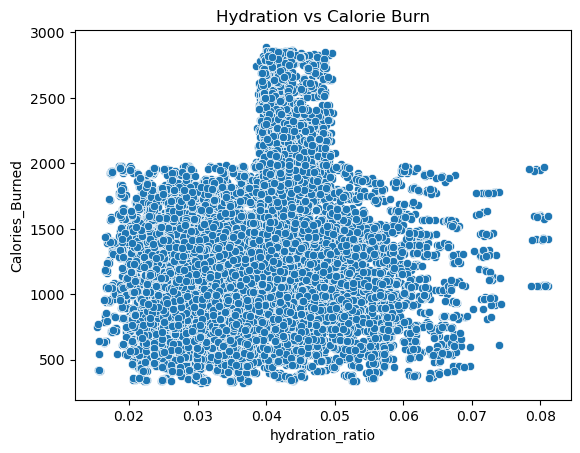

In [30]:
df['caloric_efficiency'] = df['Calories_Burned'] / df['Session_Duration_hours']
df['hydration_ratio'] = df['Water_Intake_liters'] / df['Weight_kg']

sns.histplot(df['caloric_efficiency'], kde=True)
plt.title("Caloric Efficiency (Calories Burned per Hour)")
plt.show()

sns.scatterplot(data=df, x='hydration_ratio', y='Calories_Burned')
plt.title("Hydration vs Calorie Burn")
plt.show()

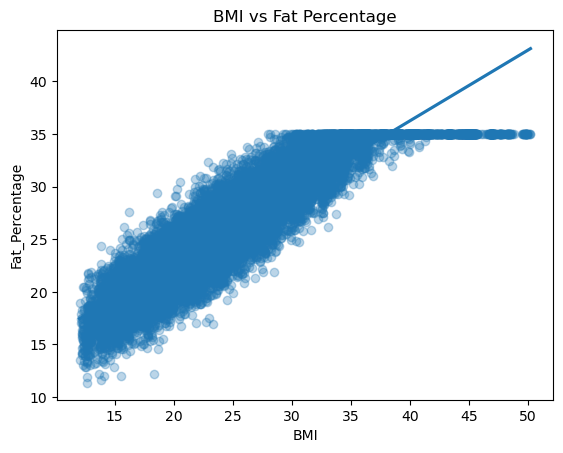

In [31]:
sns.regplot(data=df, x='BMI', y='Fat_Percentage', scatter_kws={'alpha':0.3})
plt.title("BMI vs Fat Percentage")
plt.show()

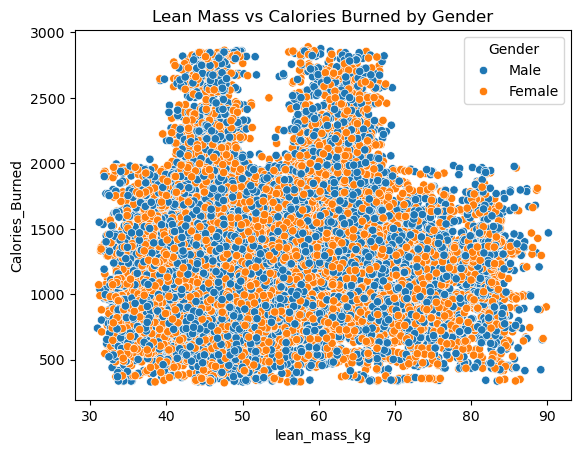

In [32]:
sns.scatterplot(data=df, x='lean_mass_kg', y='Calories_Burned', hue='Gender')
plt.title("Lean Mass vs Calories Burned by Gender")
plt.show()

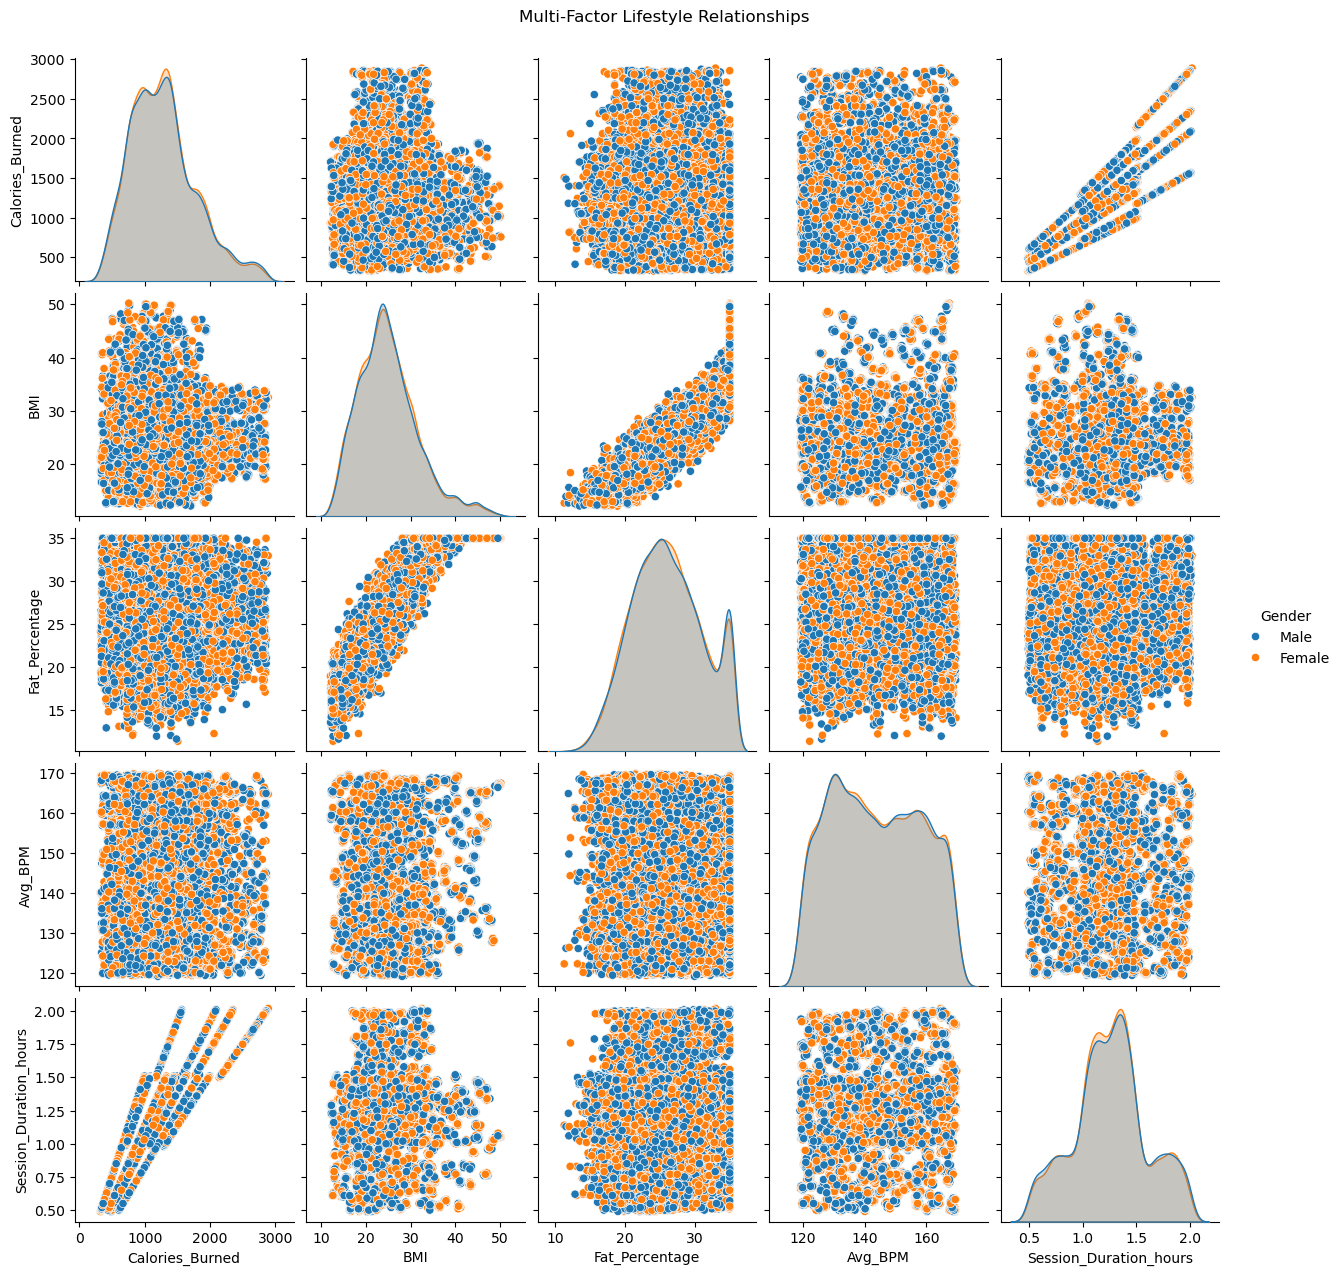

In [33]:
sns.pairplot(df, vars=['Calories_Burned', 'BMI', 'Fat_Percentage', 'Avg_BPM', 'Session_Duration_hours'], hue='Gender')
plt.suptitle("Multi-Factor Lifestyle Relationships", y=1.02)
plt.show()

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("data/Final_data.csv")
df.columns = df.columns.str.strip().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')

# General style
sns.set(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (8,5)

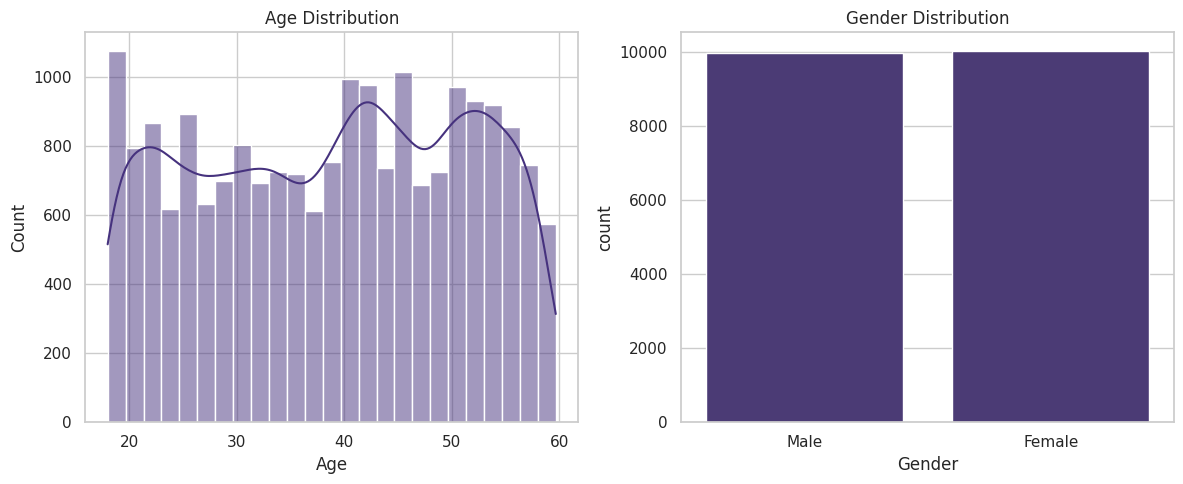

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.histplot(df['Age'], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

sns.countplot(data=df, x='Gender', ax=axes[1])
axes[1].set_title("Gender Distribution")
plt.tight_layout()
plt.show()

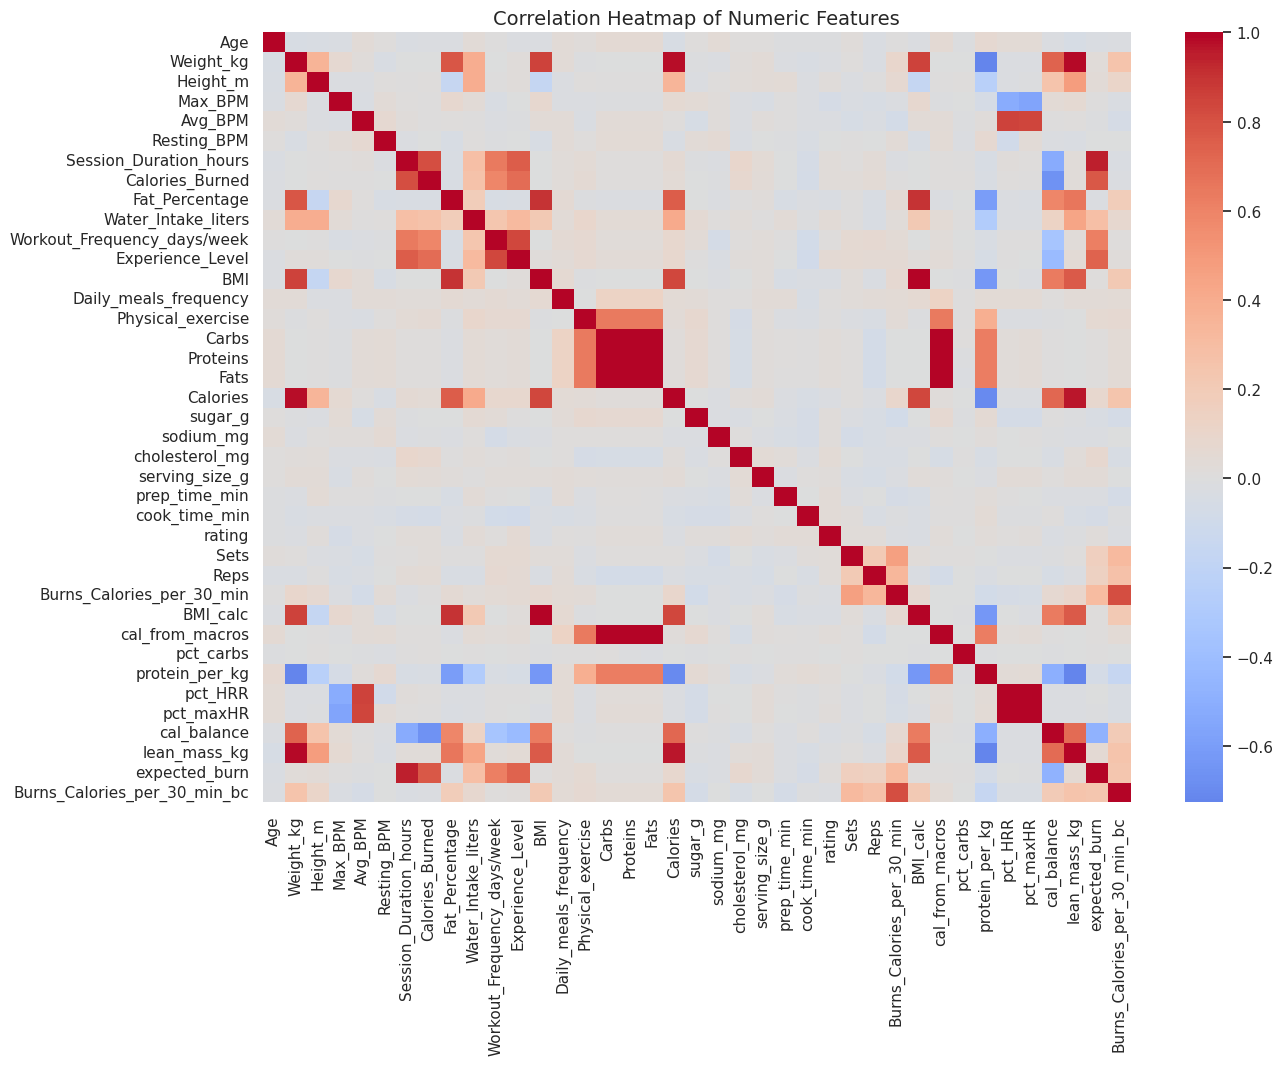

In [4]:
plt.figure(figsize=(14,10))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Features", fontsize=14)
plt.show()

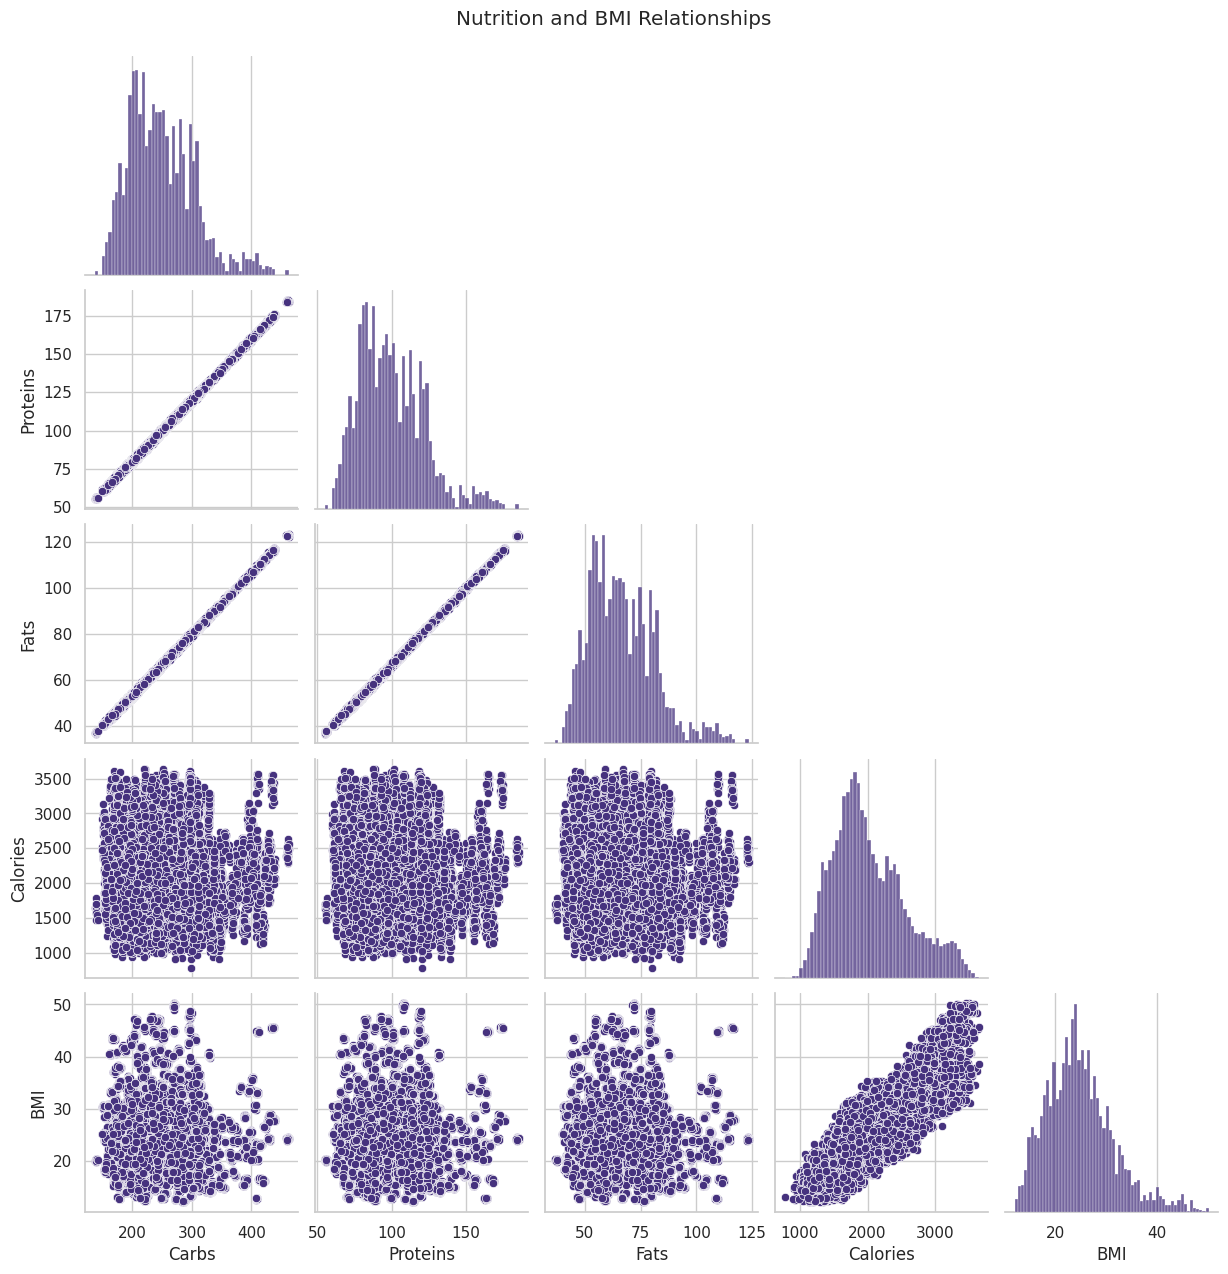

In [5]:
sns.pairplot(df, vars=['Carbs','Proteins','Fats','Calories','BMI'], corner=True)
plt.suptitle("Nutrition and BMI Relationships", y=1.02)
plt.show()

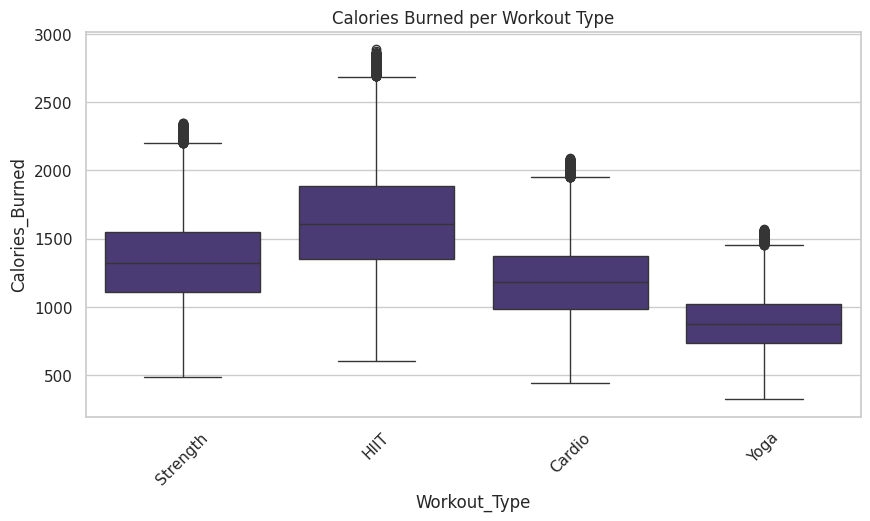

In [6]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='Workout_Type', y='Calories_Burned')
plt.xticks(rotation=45)
plt.title("Calories Burned per Workout Type")
plt.show()

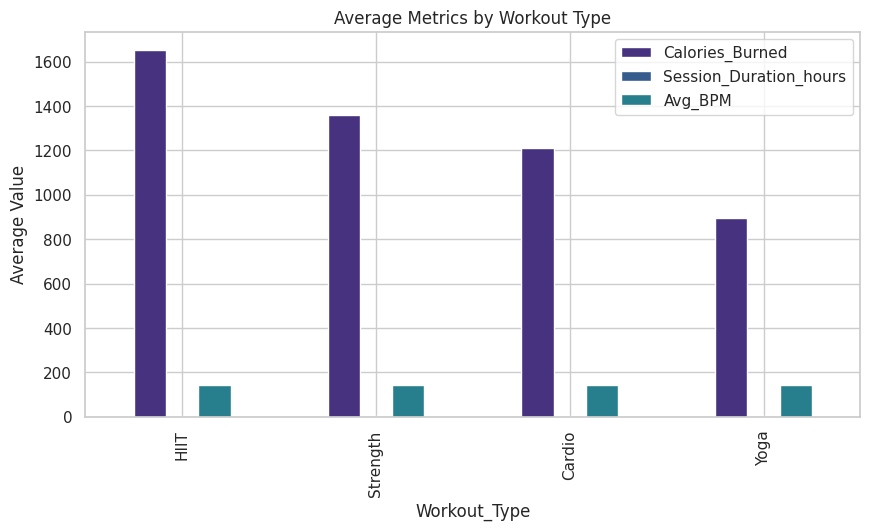

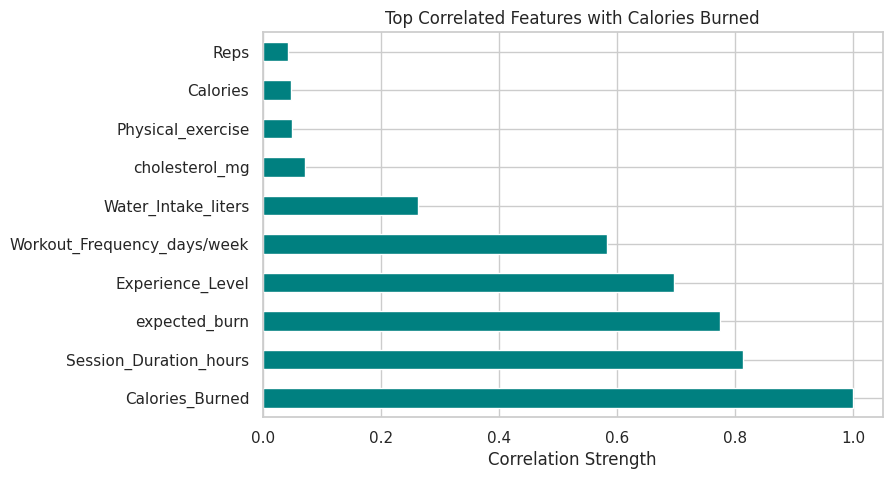

In [10]:
corr = df.corr(numeric_only=True)['Calories_Burned'].sort_values(ascending=False).head(10)
corr.plot(kind='barh', color='teal')
plt.title("Top Correlated Features with Calories Burned")
plt.xlabel("Correlation Strength")
plt.show()

# Clustering Approaches

In [3]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Pick features for clustering
features = [
    'Age', 'Weight_kg', 'Height_m', 'BMI', 'Fat_Percentage',
    'Avg_BPM', 'Session_Duration_hours', 'Calories_Burned',
    'Workout_Frequency_days/week', 'Water_Intake_liters',
    'Carbs', 'Proteins', 'Fats', 'Calories'
]

X = df[features]

# Standardize values (important for PCA/KMeans)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


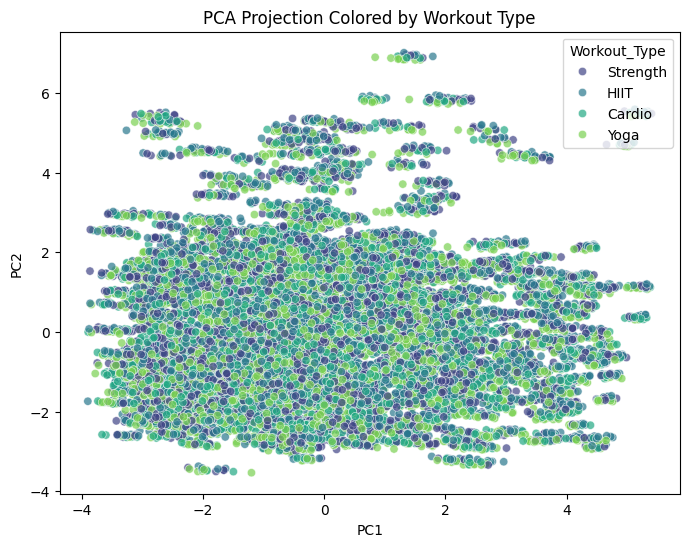

In [4]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Calories_Burned'] = df['Calories_Burned']
df_pca['Workout_Type'] = df['Workout_Type']

plt.figure(figsize=(8,6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Workout_Type', palette='viridis', alpha=0.7)
plt.title("PCA Projection Colored by Workout Type")
plt.show()


In [6]:
from sklearn.cluster import KMeans

# Choose number of clusters (e.g. 4)
kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df['Cluster'] = clusters
df_pca['Cluster'] = clusters


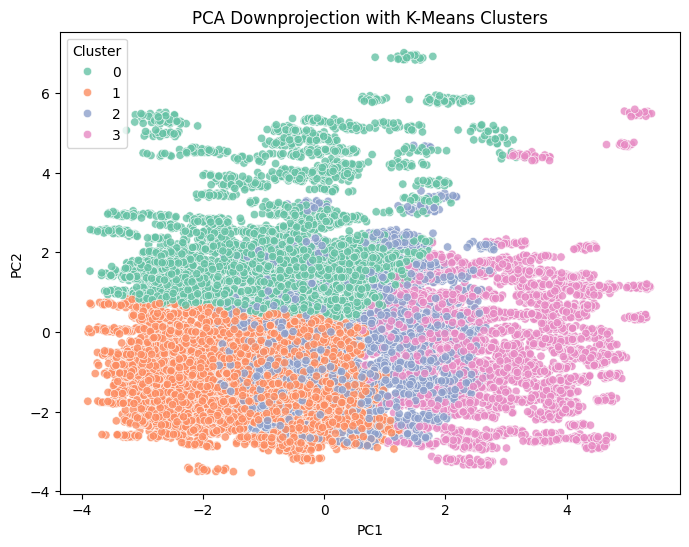

In [7]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Cluster', palette='Set2', alpha=0.8)
plt.title("PCA Downprojection with K-Means Clusters")
plt.show()

In [8]:
cluster_summary = df.groupby('Cluster')[features].mean()
cluster_summary.T

Cluster,0,1,2,3
Age,39.554849,39.094872,38.140696,38.190837
Weight_kg,64.744451,61.647240,74.829591,107.521341
Height_m,1.713754,1.687641,1.743975,1.782370
BMI,22.246872,21.866919,24.721784,34.189446
Fat_Percentage,24.269924,24.102983,25.766033,32.455112
Avg_BPM,144.287392,143.415966,142.789063,144.392193
Session_Duration_hours,1.212955,1.129104,1.718998,1.134677
Calories_Burned,1208.827132,1096.159642,1936.146458,1103.986914
Workout_Frequency_days/week,3.187806,3.034555,4.450412,2.961207
Water_Intake_liters,2.493842,2.289032,3.161105,2.935629


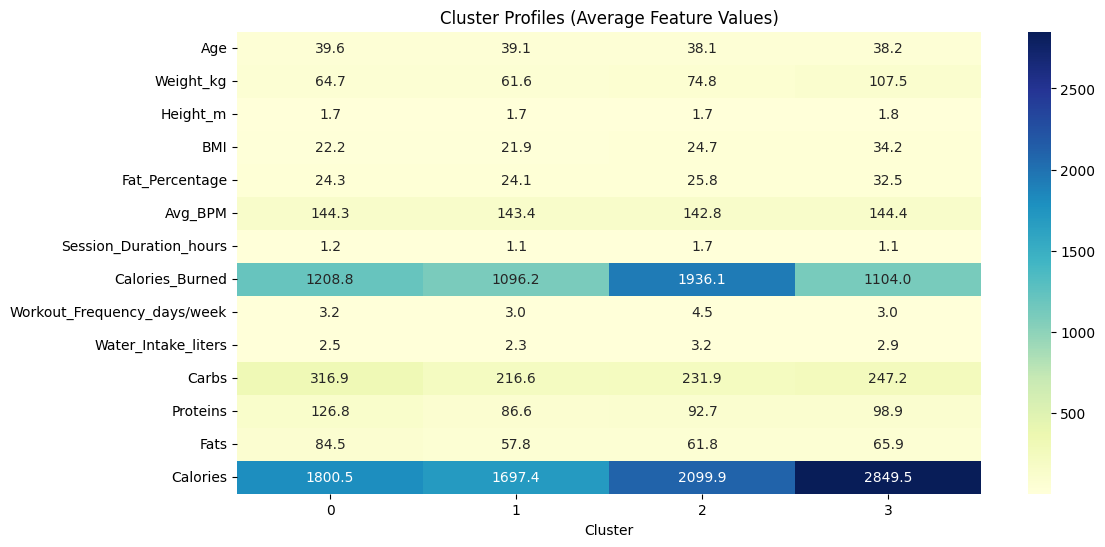

In [9]:
plt.figure(figsize=(12,6))
sns.heatmap(cluster_summary.T, cmap='YlGnBu', annot=True, fmt=".1f")
plt.title("Cluster Profiles (Average Feature Values)")
plt.show()